# Page: anchors and pivots (`editor/show_editor_state_v2.gd`)

```gdscript
button.scale = Vector2.ONE * 50
button.set_anchors_and_offsets_preset(Control.PRESET_CENTER)
panel.add_child(button)
```

**They are two separate steps.** Anchors and offsets decide where the button's *unscaled* rectangle sits in the panel. The pivot only matters afterwards, when `scale` or `rotation` transforms that rectangle. Anchors never look at scale, so centring the layout does not centre a scaled button.

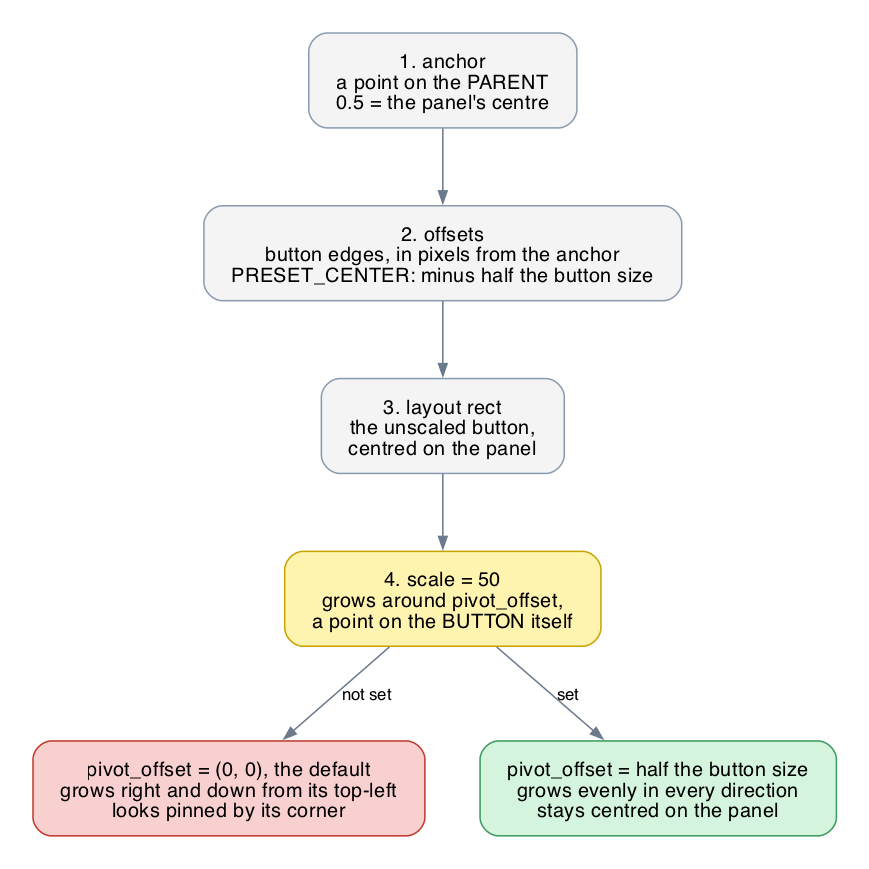

<details><summary>diagram source (graphviz)</summary>

```dot
digraph {
  rankdir=TB;
  node [shape=box, style="rounded,filled", fillcolor="#f4f4f4", fontname="Helvetica"];
  edge [fontname="Helvetica", fontsize=11];
  anchor [label="1. anchor\na point on the PARENT\n0.5 = the panel's centre"];
  offset [label="2. offsets\nbutton edges, in pixels from the anchor\nPRESET_CENTER: minus half the button size"];
  layout [label="3. layout rect\nthe unscaled button,\ncentred on the panel"];
  pivot  [label="4. scale = 50\ngrows around pivot_offset,\na point on the BUTTON itself", fillcolor="#fff3b0", color="#c9a400"];
  bad    [label="pivot_offset = (0, 0), the default\ngrows right and down from its top-left\nlooks pinned by its corner", fillcolor="#f9d0d0", color="#c0392b"];
  good   [label="pivot_offset = half the button size\ngrows evenly in every direction\nstays centred on the panel", fillcolor="#d4f4dd", color="#3c9a5f"];
  anchor -> offset -> layout -> pivot;
  pivot -> bad  [label="not set"];
  pivot -> good [label="set"];
}
```

</details>

| | Anchor | Offset | Pivot (`pivot_offset`) |
|---|---|---|---|
| What it is | a reference point | distance from the anchor to a button edge | the point `scale` and `rotation` turn around |
| Lives on | the **parent** (the panel) | between parent and button | the **button** itself |
| Unit | fraction of parent size, 0 to 1 | pixels | pixels from the button's top-left |
| How many | 4, one per edge | 4, one per edge | 1 |
| Default | 0, 0, 0, 0 (parent's top-left) | 0 | (0, 0), the button's top-left |
| Used for | layout: position and size | layout: position and size | drawing and click area, after layout |
| Ignored when | the parent is a container (e.g. `VBoxContainer`) | the parent is a container | never |

`edge position = parent_size * anchor + offset`

- **What the script shows today:** steps 1 to 3 are right, the pivot is the default, so the 50x button grows right and down from the panel's centre (the red box).
- **Keep `scale`:** add `button.pivot_offset = button.get_combined_minimum_size() / 2` (the green box).
- **Skip the pivot entirely:** drop `scale` and use `button.custom_minimum_size`; the button is then really that big, and the preset centres it exactly.
- **Order matters:** the preset computes the offsets once, from the button's size at that moment, so set the size first.

Not run in the editor: the two fixes are from how `Control` layout works, not from a test in this project.
